In [1]:
import importlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import llm_hallucination_judge as judge_mod
importlib.reload(judge_mod)
from hallucination_features import FEATURE_COLS, build_augmented_lr_pipeline, light_clean
from llm_hallucination_judge import DEFAULT_JUDGE_MODEL, classify_tiered, should_escalate
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold

In [2]:
ROUTING_THRESHOLD = 0.7
USE_CACHE = True  # True: judge labels from data/judge_cache_dataset_v1.json; False: call NIM for escalated rows
NIM_JUDGE_MODEL = os.getenv("NIM_JUDGE_MODEL", DEFAULT_JUDGE_MODEL)
RANDOM_STATE = 1
CV_FOLDS = 3

In [3]:
DATA_DIR = Path.cwd() / "data"
if not (DATA_DIR / "llm_hallucination_dataset_v1.csv").is_file():
    DATA_DIR = Path.cwd().parent / "data"
DATASET_CSV = DATA_DIR / "llm_hallucination_dataset_v1.csv"
JUDGE_CACHE_PATH = DATA_DIR / "judge_cache_dataset_v1.json"

llm_df = pd.read_csv(DATASET_CSV)
llm_df = llm_df.drop(columns=["notes"], errors="ignore")

llm_df["prompt_text"] = llm_df["prompt_text"].astype(str)
llm_df["response_text"] = llm_df["response_text"].astype(str)
llm_df["response_clean"] = llm_df["response_text"].map(light_clean)

y = llm_df["hallucination_label"]
groups = llm_df["prompt_text"]
X = llm_df[FEATURE_COLS]

In [4]:
def load_judge_cache(path: Path) -> dict[str, dict]:
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def row_sample(row_index: int) -> dict:
    meta = llm_df.loc[row_index]
    return {
        "record_id": meta.get("record_id"),
        "prompt_text": meta["prompt_text"],
        "response_text": meta["response_text"],
        "prompt_type": meta["prompt_type"],
        "task_type": meta["task_type"],
        "domain": meta.get("domain"),
        "language": meta.get("language"),
        "model_name": meta.get("model_name"),
    }


def tiered_final_label(
    sample: dict,
    lr_pred: int,
    lr_proba: list[float],
    judge_cache: dict[str, dict],
) -> int:
    if not should_escalate(lr_proba, int(lr_pred), ROUTING_THRESHOLD):
        return int(lr_pred)
    if USE_CACHE:
        rid = str(sample["record_id"])
        if rid not in judge_cache:
            raise KeyError(
                f"record_id {rid} missing from {JUDGE_CACHE_PATH}; "
                "run build_judge_cache_dataset.py or refresh the cache."
            )
        return int(judge_cache[rid]["hallucination_label"])
    result = classify_tiered(
        sample,
        lr_pred=int(lr_pred),
        lr_proba=lr_proba,
        confidence_threshold=ROUTING_THRESHOLD,
        model=NIM_JUDGE_MODEL,
        skip_network=False,
    )
    return int(result.final_label)


judge_cache: dict[str, dict] = load_judge_cache(JUDGE_CACHE_PATH) if USE_CACHE else {}
if USE_CACHE:
    dataset_rids = llm_df["record_id"].astype(str)
    missing = [rid for rid in dataset_rids if rid not in judge_cache]
    if missing:
        raise ValueError(f"{len(missing)} dataset record_id(s) missing from judge cache (first: {missing[0]})")

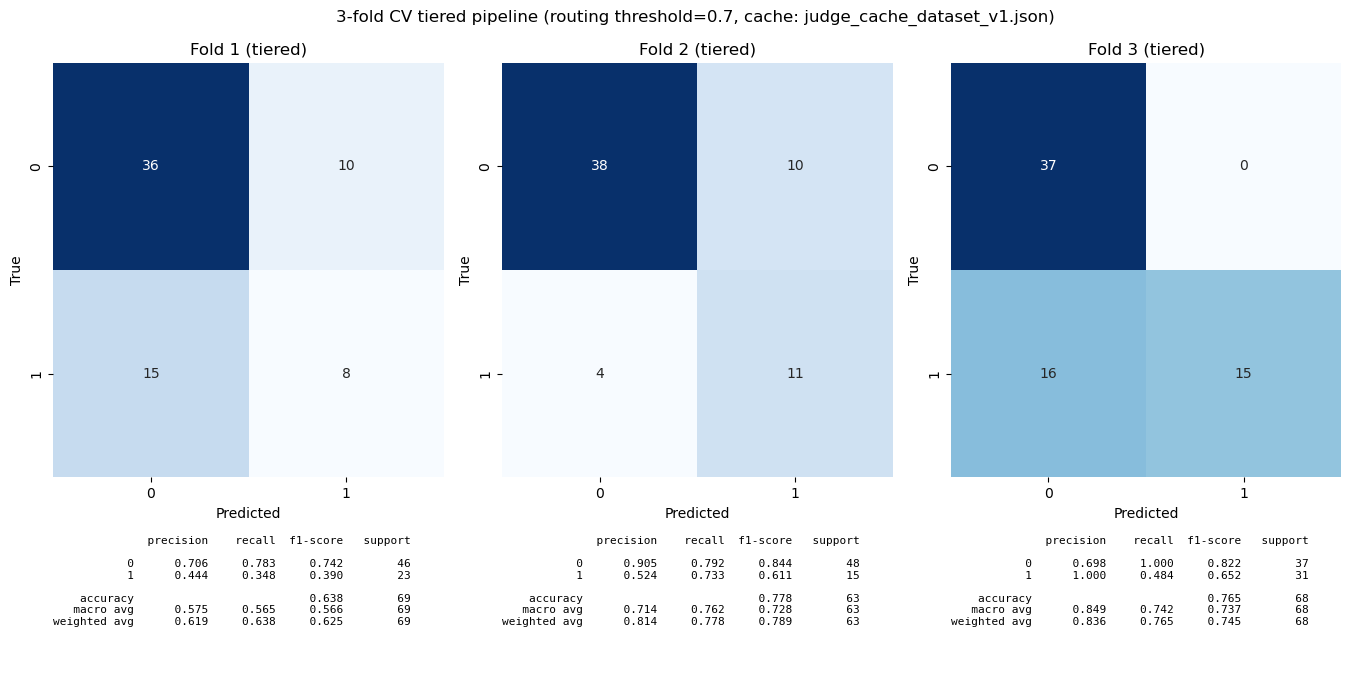

In [5]:
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
pipeline = build_augmented_lr_pipeline()

fig, axes = plt.subplots(2, 3, figsize=(14, 7), gridspec_kw={"height_ratios": [1.0, 0.35]})

fold_accuracy = []
fold_precision = []
fold_recall = []
fold_f1 = []
fold_judge_counts = []
fold_val_sizes = []

for fold_idx, (tr_idx, val_idx) in enumerate(cv.split(X, y, groups)):
    X_tr = X.iloc[tr_idx]
    y_tr = y.iloc[tr_idx]
    X_val = X.iloc[val_idx]
    y_val = y.iloc[val_idx]

    fold_pipeline = clone(pipeline)
    fold_pipeline.fit(X_tr, y_tr)
    val_proba = fold_pipeline.predict_proba(X_val)
    val_lr_pred = fold_pipeline.predict(X_val)

    y_val_pred = []
    n_judge = 0
    for i, row_index in enumerate(X_val.index):
        lr_proba = val_proba[i].tolist()
        lr_pred = int(val_lr_pred[i])
        if should_escalate(lr_proba, lr_pred, ROUTING_THRESHOLD):
            n_judge += 1
        y_val_pred.append(
            tiered_final_label(row_sample(row_index), lr_pred, lr_proba, judge_cache)
        )
    y_val_pred = np.asarray(y_val_pred, dtype=int)
    fold_judge_counts.append(n_judge)
    fold_val_sizes.append(len(y_val))

    cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=[0, 1],
        yticklabels=[0, 1],
        ax=axes[0, fold_idx],
    )
    axes[0, fold_idx].set_xlabel("Predicted")
    axes[0, fold_idx].set_ylabel("True")
    axes[0, fold_idx].set_title(f"Fold {fold_idx + 1} (tiered)")

    report = classification_report(y_val, y_val_pred, digits=3, zero_division=0)
    axes[1, fold_idx].axis("off")
    axes[1, fold_idx].text(
        0.0,
        1.0,
        report,
        transform=axes[1, fold_idx].transAxes,
        fontsize=8,
        verticalalignment="top",
        horizontalalignment="left",
        family="monospace",
    )

    fold_accuracy.append((y_val_pred == y_val.to_numpy()).mean())
    fold_precision.append(precision_score(y_val, y_val_pred, zero_division=0))
    fold_recall.append(recall_score(y_val, y_val_pred, zero_division=0))
    fold_f1.append(f1_score(y_val, y_val_pred, zero_division=0))

cache_note = f"cache: {JUDGE_CACHE_PATH.name}" if USE_CACHE else "live NIM endpoint"
fig.suptitle(
    f"{CV_FOLDS}-fold CV tiered pipeline (routing threshold={ROUTING_THRESHOLD}, {cache_note})"
)
plt.tight_layout()
plt.show()

In [6]:
for fold_idx, (n_judge, n_val) in enumerate(
    zip(fold_judge_counts, fold_val_sizes), start=1
):
    print(f"Fold {fold_idx}: {n_judge}/{n_val} rows routed to LLM judge")
print(
    f"Total: {sum(fold_judge_counts)}/{len(X)} rows routed to LLM judge"
)

Fold 1: 12/69 rows routed to LLM judge
Fold 2: 29/63 rows routed to LLM judge
Fold 3: 7/68 rows routed to LLM judge
Total: 48/200 rows routed to LLM judge


In [7]:
# Modified by Cursor
print(f"{CV_FOLDS}-fold average accuracy: {np.mean(fold_accuracy):.3f}")
print(f"{CV_FOLDS}-fold average precision: {np.mean(fold_precision):.3f}")
print(f"{CV_FOLDS}-fold average recall: {np.mean(fold_recall):.3f}")
print(f"{CV_FOLDS}-fold average f1: {np.mean(fold_f1):.3f}")

3-fold average accuracy: 0.727
3-fold average precision: 0.656
3-fold average recall: 0.522
3-fold average f1: 0.551
